In [189]:
import os
import numpy as np
import scipy.stats
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as pl
from scipy.stats import wilcoxon
import shutil
import nrrd
import cv2
import SimpleITK as sitk

In [ ]:
data_names = pd.read_excel('/Users/Francisco/Desktop/RestrepoProjects/Regeneron retrospective radiomics/databases/amine_valentin_radiomics/DLHCC_data_all_rois.xlsx')
data_mrns = pd.read_excel('/Users/Francisco/Desktop/RestrepoProjects/Regeneron retrospective radiomics/databases/amine_valentin_radiomics/DLHCC_T2&DWI_data_all_rois.xlsx')
mined_data = pd.read_excel('/Users/Francisco/Desktop/RestrepoProjects/Regeneron retrospective radiomics/databases/cases_01_27_25/valentin_intersec_SA1cases.xlsx')

# Pre-massaging
# From data_names, remove annotations done by Kazuya, for now we don't wanna do inter-reader

# Let's first work with the data containing only names
# Start with breaking the pesky names into first and last name
data_names[['Last name', 'First name']] = data_names['name'].str.split('^', expand=True)

# Then, look for last names already contained in mined_data
data_names['Last name'] = data_names['Last name'].str.lower()
data_names['First name'] = data_names['First name'].str.lower()
mined_data['First name'] = mined_data['First name'].str.lower()
mined_data['Last name'] = mined_data['Last name'].str.lower()


# Change a few col names:
data_mrns = data_mrns.rename(columns={'name': 'MRN','name.1':'Sequence','z':'Slice'})
data_names = data_names.rename(columns={'name.1':'Sequence','z':'Slice'})
mined_data = mined_data.rename(columns={'MRI Accession number':'Accession','Date of MRI exam':'MRI date'})

# For both dataframes, pick only those patients which were contained in "mined_data" (containing our inclusion criteria) 
names_filt = data_names.merge(mined_data,on = ['First name', 'Last name'], how = 'inner')
mrns_filt = data_mrns.merge(mined_data,on = ['MRN'], how = 'inner')


# Now merge all segmentations into one file; removing unnecessary columns first
names_filt.drop(names_filt.columns[[0,1,2,3,6,8]], axis=1, inplace=True)
mrns_filt.drop(mrns_filt.columns[[0,1,2,6,8]], axis=1, inplace=True)

#Re-order columns
names_filt = names_filt[['First name', 'Last name', 'MRN','Accession','MRI date','group_id','Sequence','Slice','points_array']]
mrns_filt = mrns_filt[['First name', 'Last name', 'MRN','Accession','MRI date','group_id','Sequence','Slice','points_array']]

# Now, stitch them together to get final array of all segmentations that are included in our inclusion/exclusion
total_segs = pd.concat([names_filt,mrns_filt], ignore_index=True)

total_segs = total_segs.sort_values(by=['First name','Sequence','group_id','Slice'], ascending = [False,False,False,True])

#Now, change the sequences names to reflect AP, Pre, DWI, etc...

total_segs.loc[total_segs['Sequence'].isin(mined_data['T1 Pre']), 'Sequence'] = 'T1 Pre'
total_segs.loc[total_segs['Sequence'].isin(mined_data['T1 AP (1/2)']), 'Sequence'] = 'T1 AP (1/2)'
total_segs.loc[total_segs['Sequence'].isin(mined_data['T1 PVP']), 'Sequence'] = 'T1_PVP'
total_segs.loc[total_segs['Sequence'].isin(mined_data['T1 TP']), 'Sequence'] = 'T1_TP'
total_segs.loc[total_segs['Sequence'].isin(mined_data['T1 HBP']), 'Sequence'] = 'T1_HBP'

total_segs.to_excel('/Users/Francisco/Desktop/RestrepoProjects/Regeneron retrospective radiomics/databases/cases_01_27_25/total_segs.xlsx', index=False)

In [ ]:
seg3d = np.zeros((512,512,218))
img_size = (512,512)


for i in range(4784,4811):
    # Try to convert segmentation masks in coordinate pair format to something else
    test = data_names['points_array'][i]
    slice = data_names['z'][i]

    test=test[1:-1]
    test = test.split(",")
    x = np.array(test[::2])
    y = np.array(test[1::2])
    seg = np.column_stack((x,y))
    seg = seg.astype(float)

    # Convert real-world coordinates to voxel indices
    contour_voxel = np.round(seg).astype(np.int32)
    mask = np.zeros(img_size, dtype=np.uint8)
    # Draw filled contour on mask
    mask = cv2.fillPoly(mask, [contour_voxel], color=1)

    seg3d[:,:,128-slice] = mask

# Convert NumPy array to SimpleITK image
# sitk_image = sitk.GetImageFromArray(seg3d)

# Save as NRRD
mask_nrrd_path = "/Users/Francisco/Desktop/RestrepoProjects/Regeneron retrospective radiomics/databases/cases_01_27_25/segmentation_mask.nrrd"
#sitk.WriteImage(sitk_image, mask_nrrd_path)

header = {
    'type': 'float64',
    'dimension': 3,
    'space': 'left-posterior-superior',
    'sizes': seg3d.shape,
    'endian': 'little',
    'encoding': 'gzip'
}
nrrd.write(mask_nrrd_path,seg3d,header)

print(f"Saved segmentation mask as {mask_nrrd_path}")

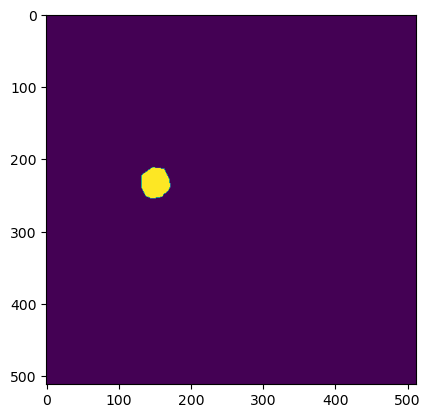

In [186]:
plt.imshow(mask)